# Cut-site prediction: ESM3Di vs base ESM++ embeddings

Leave-one-genus-out comparison of per-residue embeddings from ESM3Di against those from the
non-fine-tuned ESM++ backbone it was adapted from, on cleavage-site prediction in
*Amarillovirales* polyproteins. The two arms differ only in the embeddings: same sequences,
labels, splits, classifier, hyperparameters and seeds.

**This notebook produces panel d of Figure 2.** `paper/figure2.ipynb` reads
`results/esm3di_vs_esmpp_standardised/roc_curves_by_genus.png` through its `PANEL_D_IMAGE`
constant.

Features are z-scored per dimension using training-fold statistics (`--standardise`, fitted
inside each fold so nothing leaks across the split). Without it the two arms, which occupy
different numerical ranges, train under different effective learning rates and
regularisation for the same fixed hyperparameters — a confound in the one thing the
experiment holds constant. `cutsite_esm3di_vs_esmpp_raw.ipynb` is the same run without that
option; section 4 compares them.

Note that this is a controlled comparison, not a description of the released cutting model,
which is trained on all four genera rather than held out.

This notebook is a thin driver: the work lives in `scripts/run_comparison.py` (the
comparison) and `scripts/make_paper_figures.py` (the figures and tables), so the notebook
and the command line cannot drift apart.

| | |
|---|---|
| Dataset | 86 ICTV-annotated polyprotein records, four genera |
| Labels | `FT SITE` features annotated `/note="Cleavage"`; records without annotation excluded |
| Split | leave-one-genus-out, whole sequences |
| Embeddings | 1024-residue windows, 128 overlap, as `ESM3DiPredictor` computes them |
| Features | per-dimension z-score, training-fold statistics |
| Head | FFN 256→128, dropout 0.45/0.10, AdamW lr 1e-3 wd 3e-4, batch 2048, 12 epochs |
| Seeds | 1–10 |

**Reproducibility.** `--fast-loader` keeps the training fold on the GPU instead of streaming
it through a `DataLoader`. It trains the same model about 25x faster, but draws its batch
order from the device RNG, so results are statistically equivalent to the default path
rather than bit-identical.

**Why ten seeds.** The seed fixes only the head initialisation, dropout masks and batch
order — not the embeddings, the split or the labels. Re-running a single seed on different
hardware moved ROC AUC by up to 0.025, which is larger than most of the ESM3Di-vs-base
differences, so a one-seed result cannot separate signal from retraining noise.

In [1]:
import json, os, shutil, subprocess, sys, time
from pathlib import Path

import pandas as pd

HERE     = Path.cwd()                                        # .../polyprotein_cut
SCRIPTS  = HERE / "scripts"
RESULTS  = HERE / "results" / "esm3di_vs_esmpp_standardised"  # small artefacts, kept in the repo
RAWRUN   = HERE / "results" / "esm3di_vs_esmpp_raw"           # same run without --standardise
SEEDS    = "1,2,3,4,5,6,7,8,9,10"
EPOCHS   = "12"
N_FITS   = 4 * 2 * len(SEEDS.split(","))   # genera x arms x seeds

# Everything heavy is rebuilt from scratch on every run of this notebook, so that running
# it top to bottom reproduces the result rather than reading back an earlier one.
# FRESH=0 reuses the run directory, for iterating on the figures alone.
FRESH   = os.environ.get("CUTSITE_FRESH", "1") == "1"
SCRATCH = Path(os.environ.get("CUTSITE_SCRATCH", f"/scratch/{os.environ['USER']}/cutsite_standardised"))
RUN, CACHE  = SCRATCH / "run", SCRATCH / "embeddings"
PREDICTIONS = RUN / "oof_ffn_predictions.csv"          # ~200 MB: stays on scratch

for d in (RUN, CACHE, RESULTS):
    d.mkdir(parents=True, exist_ok=True)
# The clearing happens in the run cell, not here, so that opening this notebook and
# initialising the paths cannot destroy a completed run.

sys.path.insert(0, str(SCRIPTS))
print(f"fresh run: {FRESH}")
print("scripts  ", SCRIPTS)
print("run dir  ", RUN)
print("cache    ", CACHE)
print("results  ", RESULTS)

fresh run: True
scripts   /users/fweikert/ESM3di/experiments/analyses/polyprotein_cut/scripts
run dir   /scratch/fweikert/cutsite_standardised/run
cache     /scratch/fweikert/cutsite_standardised/embeddings
results   /users/fweikert/ESM3di/experiments/analyses/polyprotein_cut/results/esm3di_vs_esmpp_standardised


## 1. Environment

`run_comparison.py` uses scikit-learn for ROC AUC and average precision. A GPU is needed for
the embeddings (~20 s per arm); with `--fast-loader` the head training is roughly 1 s per
genus × arm × seed instead of ~15 s.

In [2]:
import torch
print("torch", torch.__version__, "| cuda:", torch.cuda.is_available(),
      torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")
import sklearn
print("scikit-learn", sklearn.__version__)

torch 2.14.1+cu130 | cuda: True NVIDIA A100-PCIE-40GB MIG 3g.20gb
scikit-learn 1.9.1


## 2. The ESM3Di checkpoint

The run uses the published PEFT adapter from the Hugging Face repo, resolved cache-first
exactly as `src/esm3di/inference/predictor.py` does.

The earlier single-seed run used a local `esm3di_from_mlm/epoch_5.pt` (sha256 `4e8143a4…`)
that is not on this machine. The two could not be shown equivalent, because re-running one
seed moves even the unchanged base arm by up to 0.025. Results here are internally
consistent but are **not** directly comparable with `results/esm3di_vs_esmpp/`.

In [3]:
from huggingface_hub import snapshot_download

def resolve_adapter(repo_id="cactuskid13/ESM3di_Small_MLM_3di", revision=None):
    patterns = ["hf_compatible", "hf_compatible/**"]
    try:
        root = snapshot_download(repo_id=repo_id, revision=revision,
                                 allow_patterns=patterns, local_files_only=True)
    except Exception:
        root = snapshot_download(repo_id=repo_id, revision=revision,
                                 allow_patterns=patterns, local_files_only=False)
    return Path(root) / "hf_compatible"

ADAPTER = resolve_adapter()
print("adapter", ADAPTER)
print(json.load(open(ADAPTER / "adapter_config.json"))["base_model_name_or_path"],
      "| r, alpha, dropout:",
      *[json.load(open(ADAPTER / "adapter_config.json"))[k] for k in ("r", "lora_alpha", "lora_dropout")])

adapter /users/fweikert/.cache/huggingface/hub/models--cactuskid13--ESM3di_Small_MLM_3di/snapshots/b32e8d308efd435be015122d7a1ca8f2dc671e86/hf_compatible
Synthyra/ESMplusplus_small | r, alpha, dropout: 16 32.0 0.01


## 3. Run the comparison

Extracts per-residue embeddings for both arms and trains the head for every
genus × arm × seed: 4 genera × 2 arms × 10 seeds = 80 fits. Nothing is reused — the run directory and the
embedding cache are cleared first.

In [4]:
if FRESH:
    for d in (RUN, CACHE):                 # no cached embeddings, no partial metrics
        if d.exists():
            shutil.rmtree(d)
        d.mkdir(parents=True, exist_ok=True)
    print("cleared the run directory and the embedding cache\n")

cmd = [sys.executable, str(SCRIPTS / "run_comparison.py"),
       "--adapter", str(ADAPTER), "--seeds", SEEDS, "--architectures", "ffn",
       "--epochs", EPOCHS, "--fast-loader", "--standardise",
       "--cache-dir", str(CACHE), "--output-dir", str(RUN)]
print(" ".join(cmd), "\n", flush=True)

t0 = time.time()
noise = ("Loading weights", "Attention backend", "UserWarning", "torch.from_numpy",
         "warnings.warn", "  x = torch")
with subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                      text=True, bufsize=1) as proc:
    for line in proc.stdout:
        if not any(n in line for n in noise):
            print(line.rstrip(), flush=True)
if proc.returncode:
    raise RuntimeError(f"run_comparison.py exited {proc.returncode}")
print(f"\nembeddings + {N_FITS} head trainings in {(time.time() - t0) / 60:.1f} min")

cleared the run directory and the embedding cache

/scratch/fweikert/envs/esm3di-test/bin/python /users/fweikert/ESM3di/experiments/analyses/polyprotein_cut/scripts/run_comparison.py --adapter /users/fweikert/.cache/huggingface/hub/models--cactuskid13--ESM3di_Small_MLM_3di/snapshots/b32e8d308efd435be015122d7a1ca8f2dc671e86/hf_compatible --seeds 1,2,3,4,5,6,7,8,9,10 --architectures ffn --epochs 12 --fast-loader --standardise --cache-dir /scratch/fweikert/cutsite_standardised/embeddings --output-dir /scratch/fweikert/cutsite_standardised/run 

Dataset groups: {'Hepacivirus-CHH': 15, 'Orthoflavivirus-CHH': 31, 'Pegivirus-CHH': 21, 'Pestivirus-CHH': 19}
Annotated proteins: 86 residues: 287411 cut sites: 800 device: cuda
esm3di: 1/86 sequences, 0.5s
esm3di: 5/86 sequences, 1.4s
esm3di: 9/86 sequences, 2.5s
esm3di: 13/86 sequences, 3.4s
esm3di: 17/86 sequences, 4.5s
esm3di: 21/86 sequences, 5.5s
esm3di: 25/86 sequences, 6.5s
esm3di: 29/86 sequences, 7.6s
esm3di: 33/86 sequences, 8.6s
esm3di:

### Keep the small artefacts in the repository

Everything except the predictions file is a few kB.

In [5]:
for name in ("seed_metrics.csv", "summary.csv", "run_metadata.json"):
    src = RUN / name
    if src.exists():
        shutil.copy2(src, RESULTS / name); print("copied", name)

met = pd.read_csv(RESULTS / "seed_metrics.csv"); met = met[met.architecture == "ffn"]
assert len(met) == N_FITS, f"expected {N_FITS} rows, found {len(met)}"
print(f"\n{len(met)} rows | seeds {sorted(met.seed.unique())} | "
      f"genera {sorted(met.heldout_group.unique())}")
meta = json.load(open(RESULTS / "run_metadata.json"))
print(f"fast_loader={meta['fast_loader']} | standardise={meta['standardise']} | "
      f"epochs={meta['heads']['ffn']['epochs']} | batch={meta['ffn_batch_size']}")

copied seed_metrics.csv
copied summary.csv
copied run_metadata.json

80 rows | seeds [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)] | genera ['Hepacivirus-CHH', 'Orthoflavivirus-CHH', 'Pegivirus-CHH', 'Pestivirus-CHH']
fast_loader=True | standardise=True | epochs=12 | batch=2048


## 4. Results

ROC AUC per held-out genus, and the paired within-seed difference. Both arms share each
seed, so they get identical head initialisation, dropout masks and batch order; the paired
difference therefore isolates the effect of the embeddings.

In [6]:
import numpy as np

print("ROC AUC, mean +/- sd over seeds\n")
print(f"{'genus':22s}{'ESM++ base':>18s}{'ESM3Di':>18s}{'delta':>9s}{'  seeds won'}")
per_genus = []
for g, s in met.groupby("heldout_group"):
    b = s[s.embedding_source == "esmpp_base"].set_index("seed").roc_auc.sort_index()
    e = s[s.embedding_source == "esm3di"].set_index("seed").roc_auc.sort_index()
    d = (e - b).dropna(); per_genus.append(d.mean())
    print(f"{g:22s}{b.mean():11.4f}±{b.std():.4f}{e.mean():11.4f}±{e.std():.4f}"
          f"{d.mean():+9.4f}   {(d > 0).sum()}/{len(d)}")
per_genus = np.array(per_genus)
print(f"\nmean over genera {per_genus.mean():+.4f}  sd {per_genus.std(ddof=1):.4f}  "
      f"genera won {(per_genus > 0).sum()}/4")
print("\nThe generalisation unit is the genus, so n = 4; the per-seed spread describes "
      "retraining noise, not sampling over viruses.")

ROC AUC, mean +/- sd over seeds

genus                         ESM++ base            ESM3Di    delta  seeds won
Hepacivirus-CHH            0.8449±0.0113     0.8666±0.0102  +0.0217   9/10
Orthoflavivirus-CHH        0.8854±0.0199     0.9128±0.0110  +0.0273   10/10
Pegivirus-CHH              0.8273±0.0115     0.8838±0.0104  +0.0564   10/10
Pestivirus-CHH             0.8347±0.0173     0.8985±0.0195  +0.0638   10/10

mean over genera +0.0423  sd 0.0209  genera won 4/4

The generalisation unit is the genus, so n = 4; the per-seed spread describes retraining noise, not sampling over viruses.


In [7]:
# Raw against standardised features: same dataset, same seeds, one option apart.
def fold_means(path):
    d = pd.read_csv(path / "seed_metrics.csv")
    d = d[(d.architecture == "ffn") & (d.seed.isin(met.seed.unique()))]
    return d.groupby(["heldout_group", "embedding_source"]).roc_auc.mean().unstack()

runs = {"raw features": RAWRUN, "standardised features": RESULTS}
runs = {k: v for k, v in runs.items() if (v / "seed_metrics.csv").exists()}

table = {}
for name, path in runs.items():
    f = fold_means(path)
    table[(name, "base")] = f.esmpp_base
    table[(name, "ESM3Di")] = f.esm3di
    table[(name, "delta")] = f.esm3di - f.esmpp_base
out = pd.DataFrame(table)
out.columns = pd.MultiIndex.from_tuples(out.columns)
print(out.round(4).to_string())
print()
for name in runs:
    print(f"{name:28s} mean delta over genera {out[(name, 'delta')].mean():+.4f}  "
          f"genera won {(out[(name, 'delta')] > 0).sum()}/4")
print("\nThe two differ only in --standardise; retraining noise for this task "
      "is ~0.01-0.02 ROC AUC per genus.")

                    raw features                 standardised features                
                            base  ESM3Di   delta                  base  ESM3Di   delta
heldout_group                                                                         
Hepacivirus-CHH           0.8487  0.8686  0.0199                0.8449  0.8666  0.0217
Orthoflavivirus-CHH       0.8725  0.8943  0.0217                0.8854  0.9128  0.0273
Pegivirus-CHH             0.8157  0.8597  0.0441                0.8273  0.8838  0.0564
Pestivirus-CHH            0.8485  0.8664  0.0178                0.8347  0.8985  0.0638

raw features                 mean delta over genera +0.0259  genera won 4/4
standardised features        mean delta over genera +0.0423  genera won 4/4

The two differ only in --standardise; retraining noise for this task is ~0.01-0.02 ROC AUC per genus.


## 5. Figures and tables

`make_paper_figures.py` writes Fig. 2d plus the alternative panels and the supplementary
outputs into `RESULTS`. It asserts that the inset table stays below the identity line and
that the legend covers no curve, so a later restyle fails loudly rather than silently
overlapping.

In [8]:
cmd = [sys.executable, str(SCRIPTS / "make_paper_figures.py"),
       "--results-dir", str(RESULTS)]
if PREDICTIONS.exists():
    cmd += ["--predictions", str(PREDICTIONS)]
else:
    print(f"{PREDICTIONS} not found - the ROC panel and pick distances will be skipped\n")
proc = subprocess.run(cmd, text=True, capture_output=True)
print(proc.stdout)
if proc.returncode:
    print(proc.stderr[-2000:]); raise RuntimeError("make_paper_figures.py failed")

80 rows, architecture ffn, seeds [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]

  wrote supp_table_metrics.csv

  mean over the four genera (paired, ESM3Di - base):
    ROC AUC           0.848 -> 0.890   delta +0.042   genera 4/4
    AP                0.109 -> 0.117   delta +0.008   genera 2/4
    AP ±2             0.113 -> 0.127   delta +0.014   genera 3/4
    AP ±5             0.126 -> 0.146   delta +0.020   genera 3/4
    top-10 recovery   0.323 -> 0.369   delta +0.046   genera 3/4

  wrote paired_roc_auc.{png,pdf,svg}
  wrote paired_delta.{png,pdf,svg}

5,748,220 prediction rows, seeds [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]
  legend clears the curves by 0.017
  wrote roc_curves_by_genus.{png,pdf,svg}
  wrote supp_table_pick_distances.csv
distance (residues)  ESM++ base (%)  ESM3Di (%)
              exact  

Fig. 2d  (paper/figure2.ipynb picks this file up via PANEL_D_IMAGE)


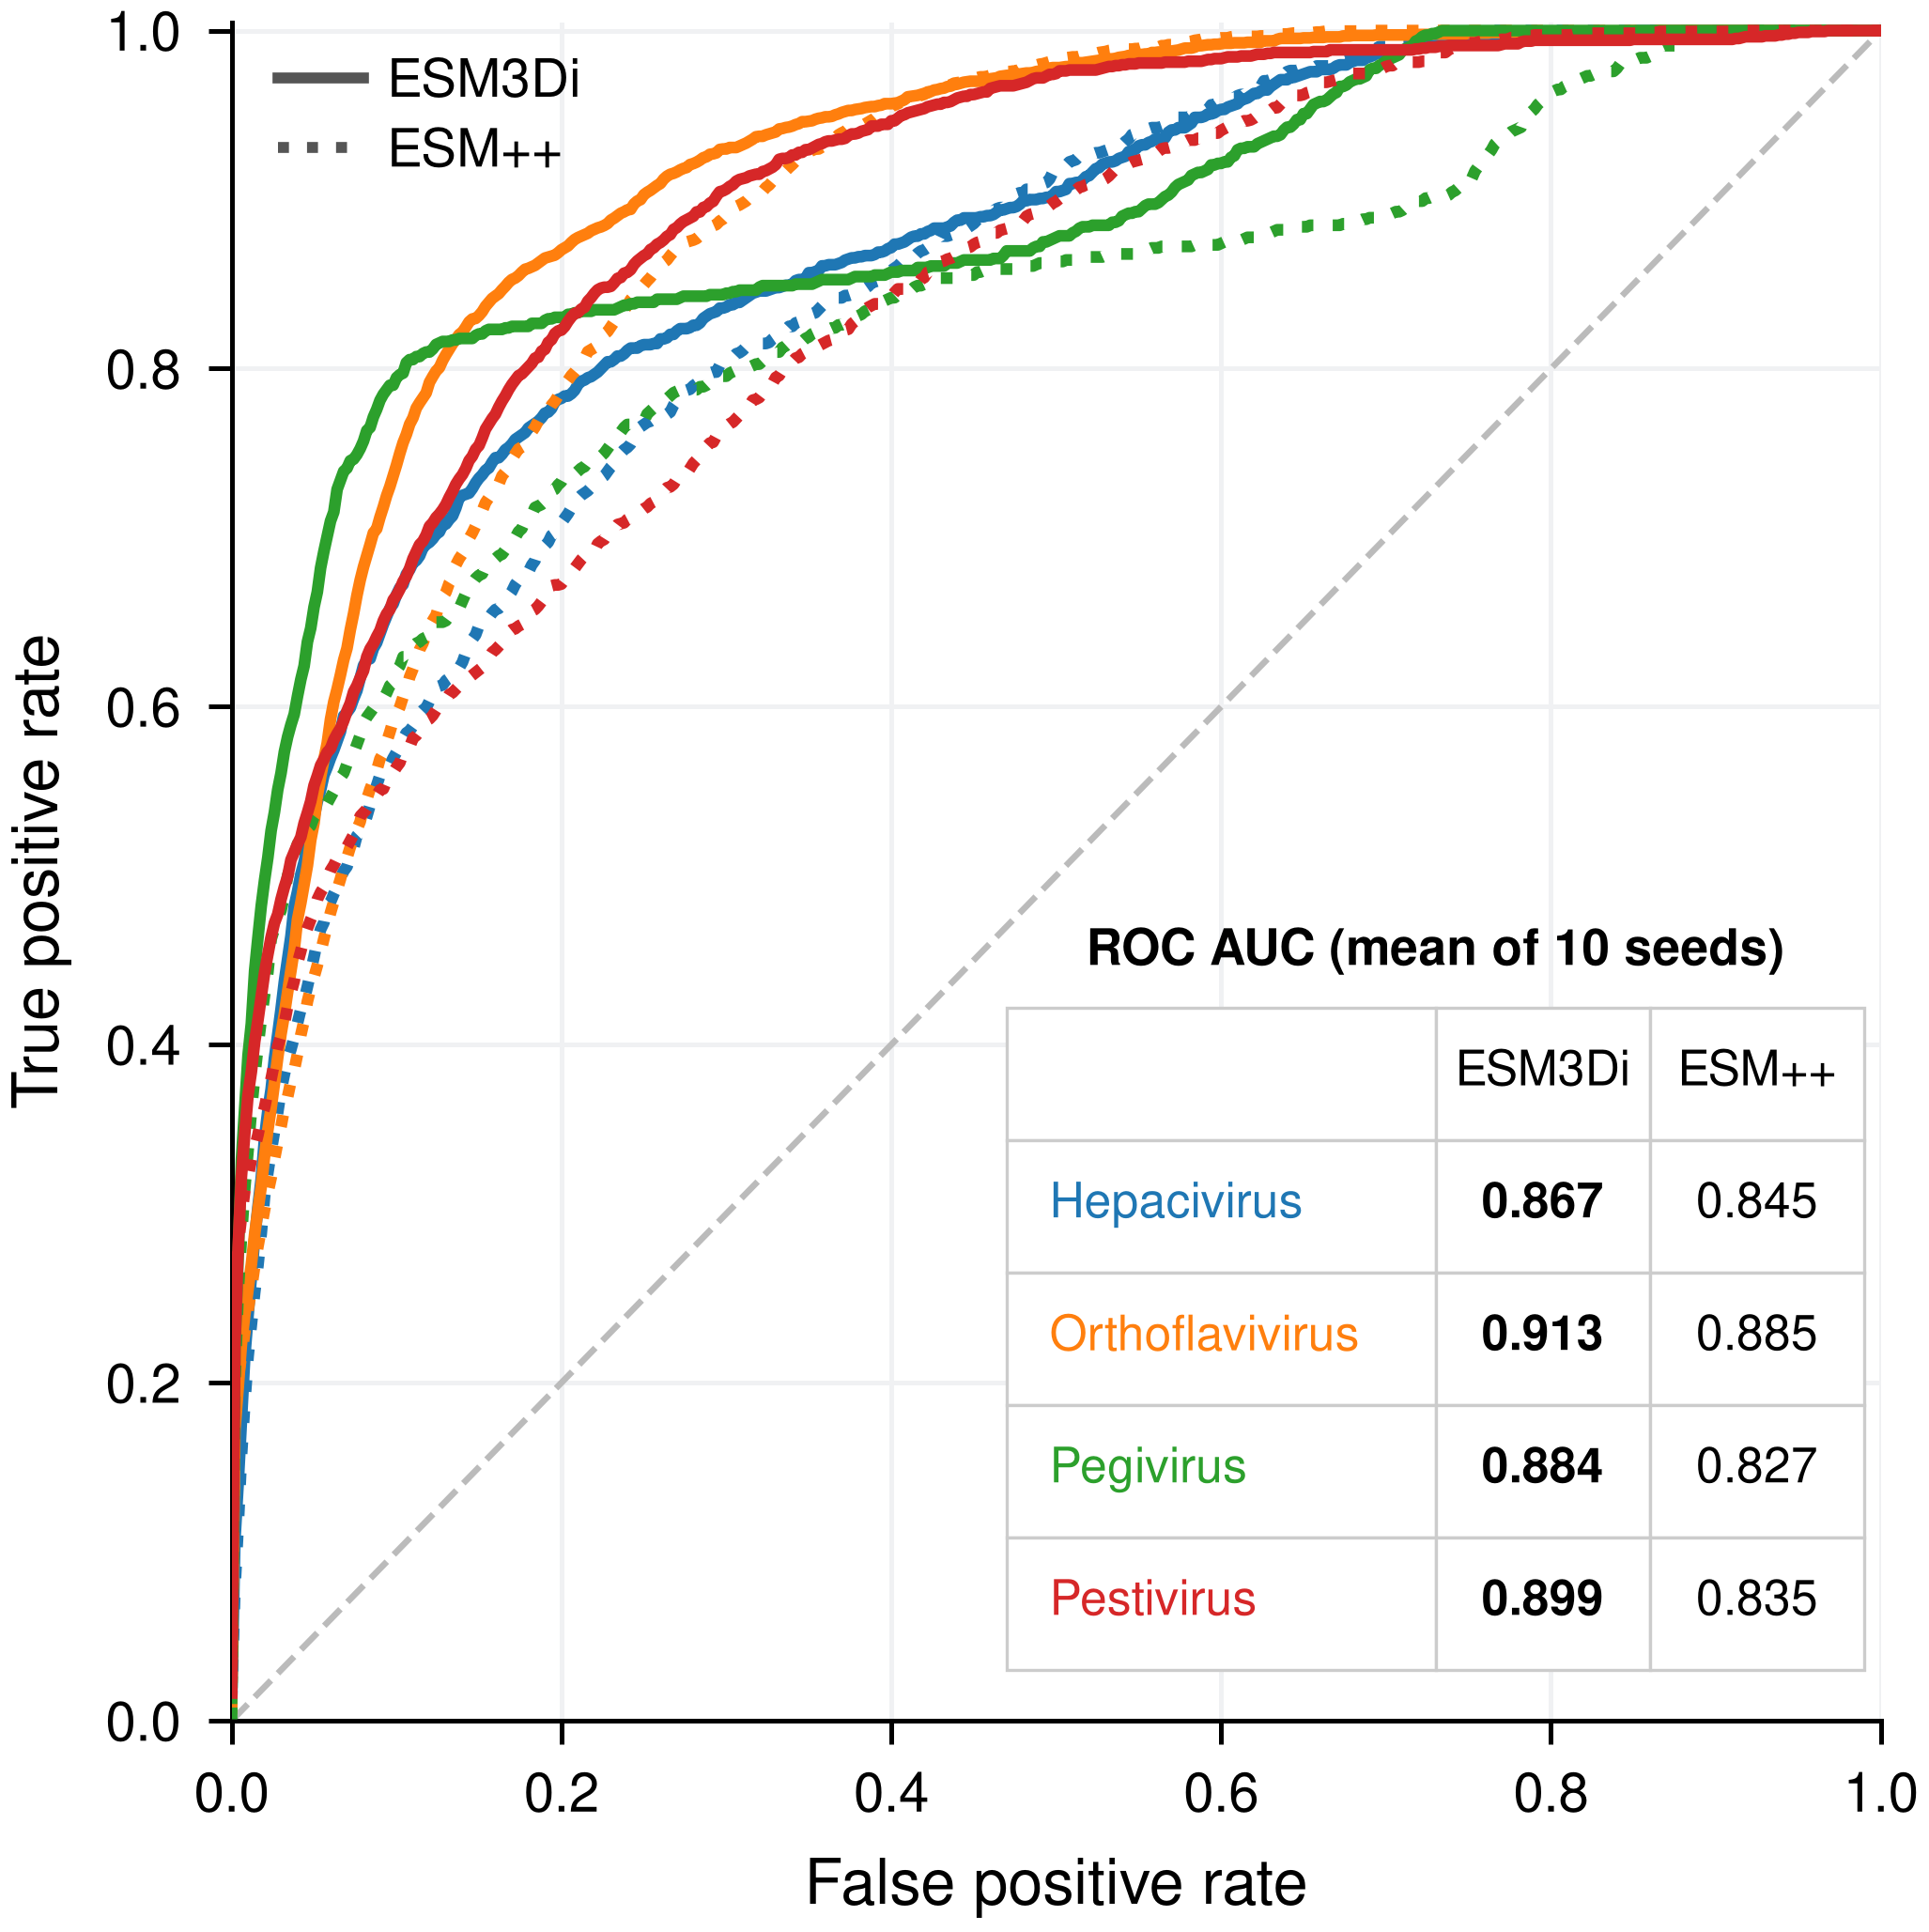

In [9]:
from IPython.display import Image, display
panel = RESULTS / "roc_curves_by_genus.png"
if panel.exists():
    print("Fig. 2d  (paper/figure2.ipynb picks this file up via PANEL_D_IMAGE)")
    display(Image(filename=str(panel), width=430))

paired_roc_auc.png


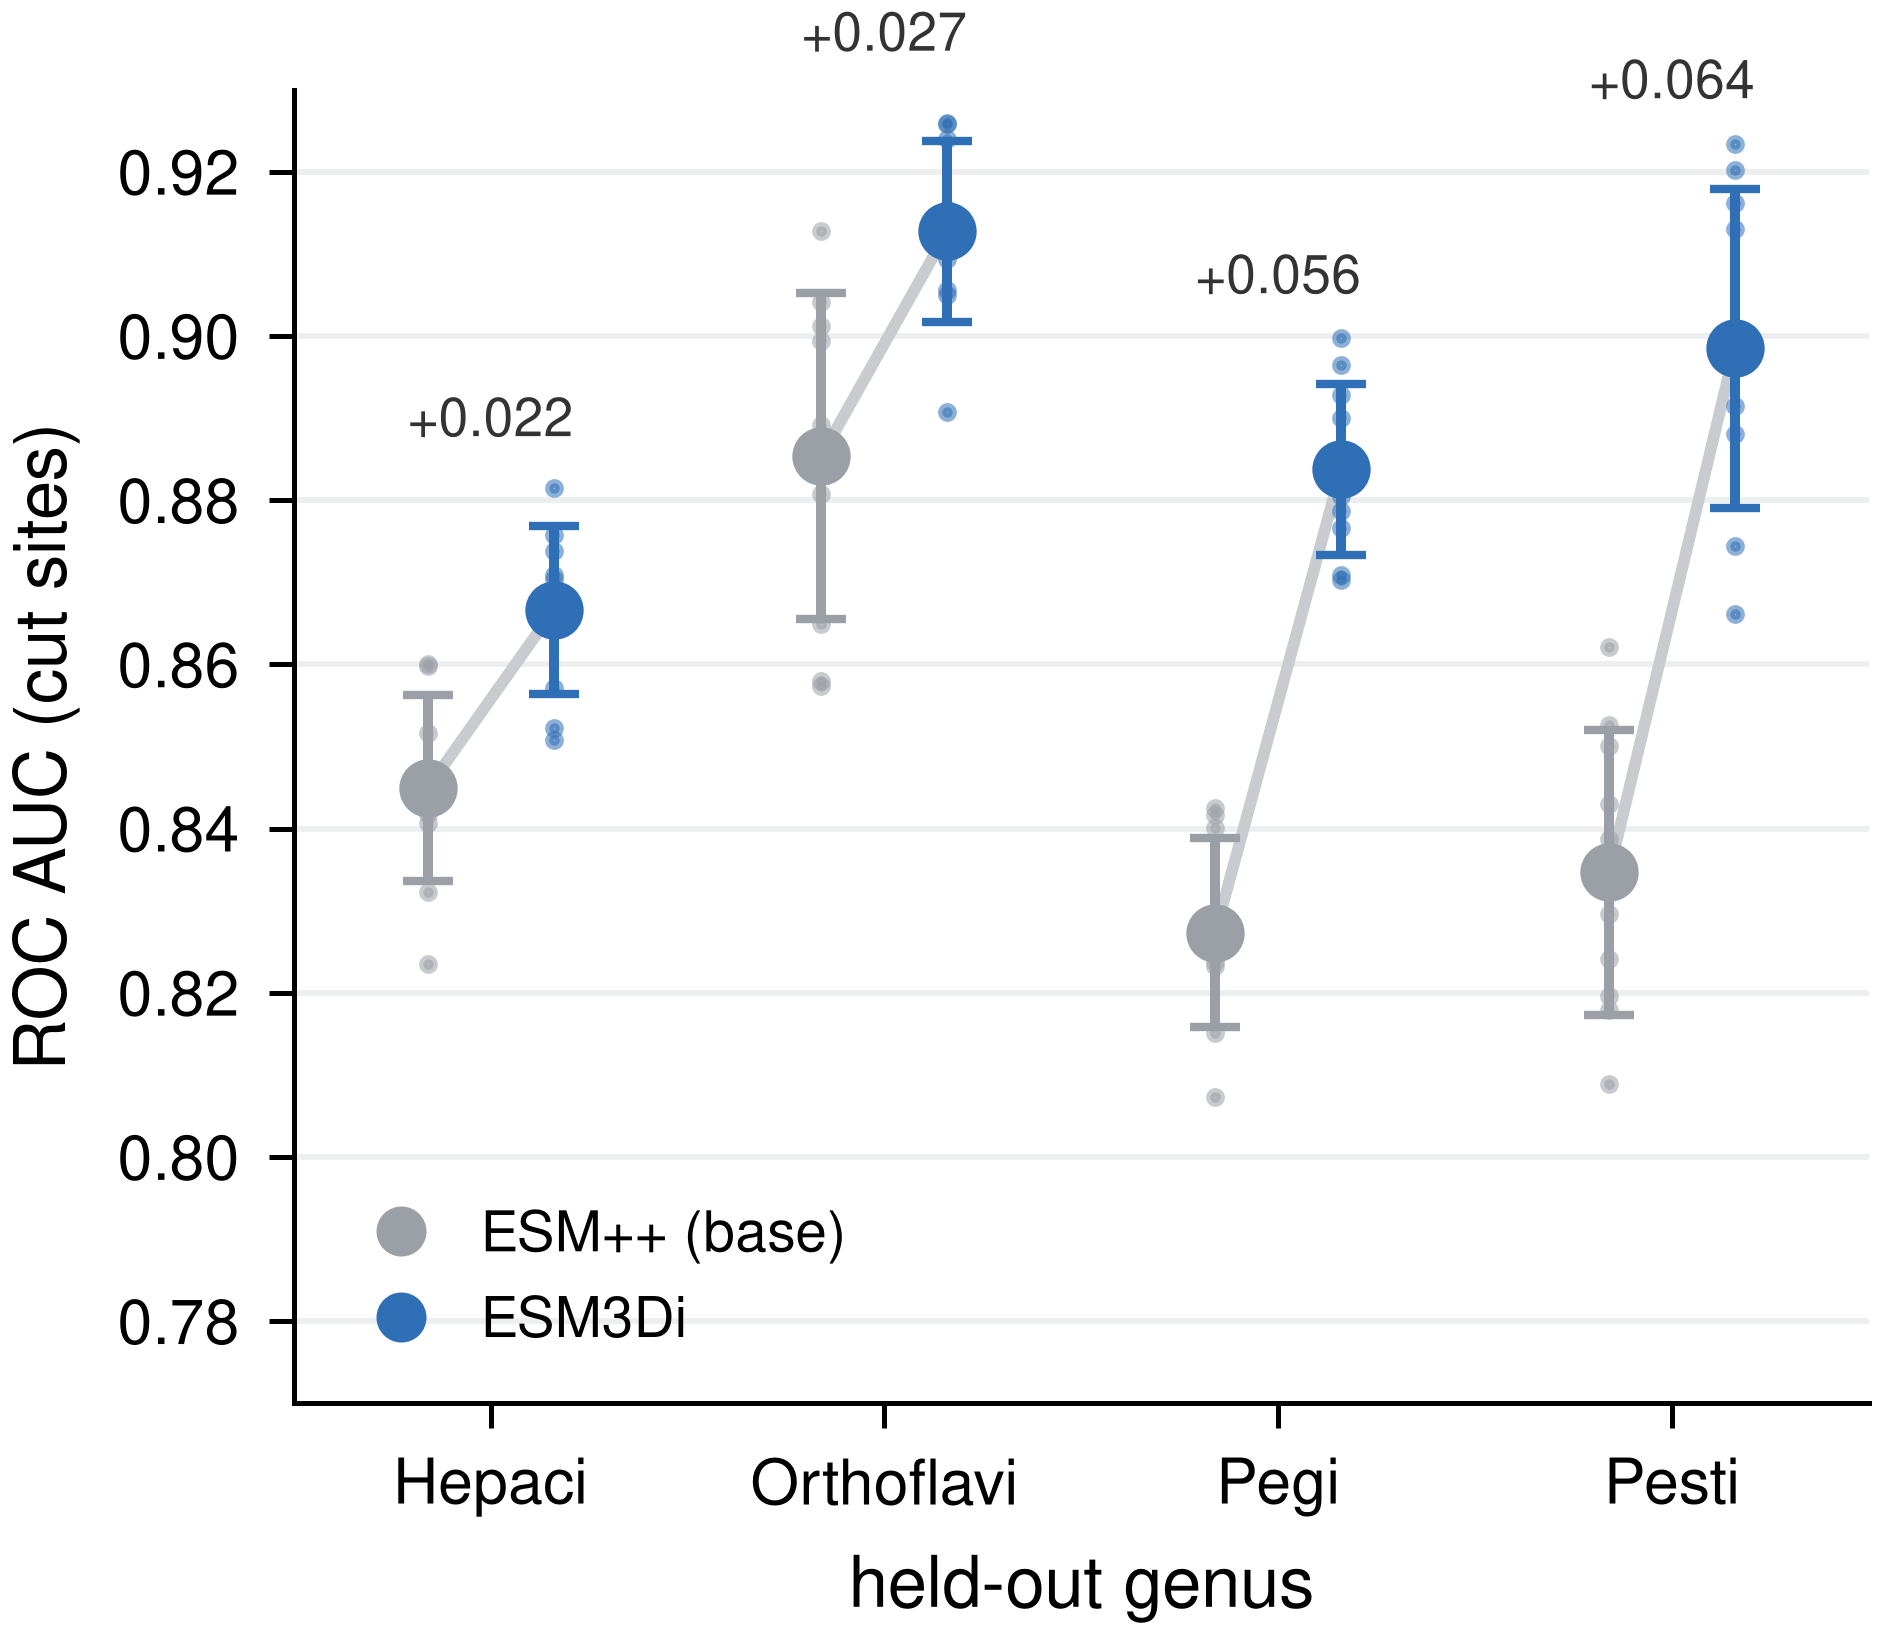

paired_delta.png


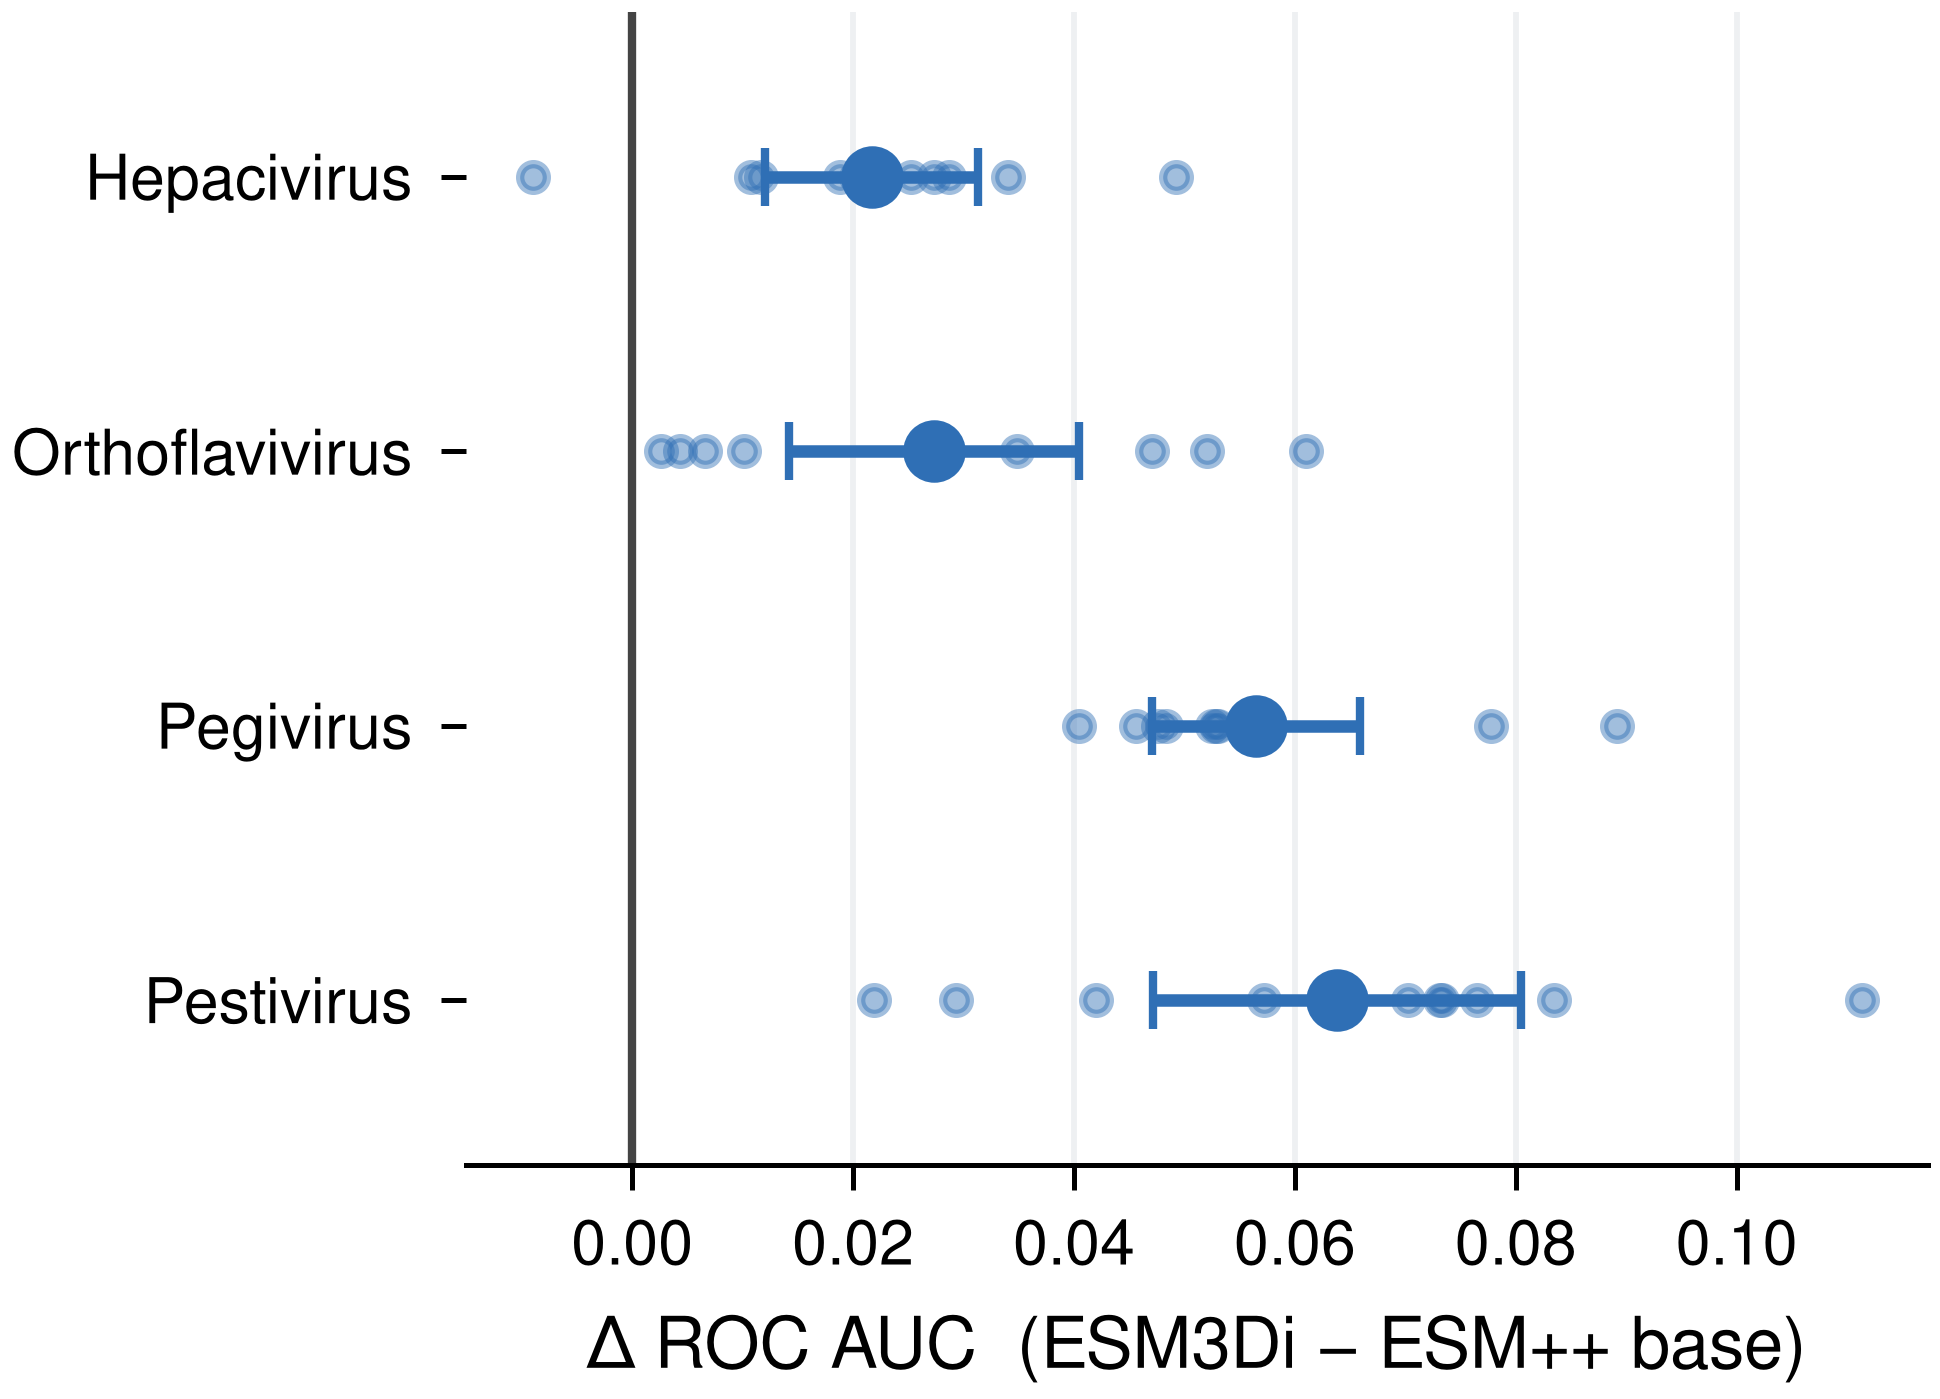

supp_fig_pick_distances.png


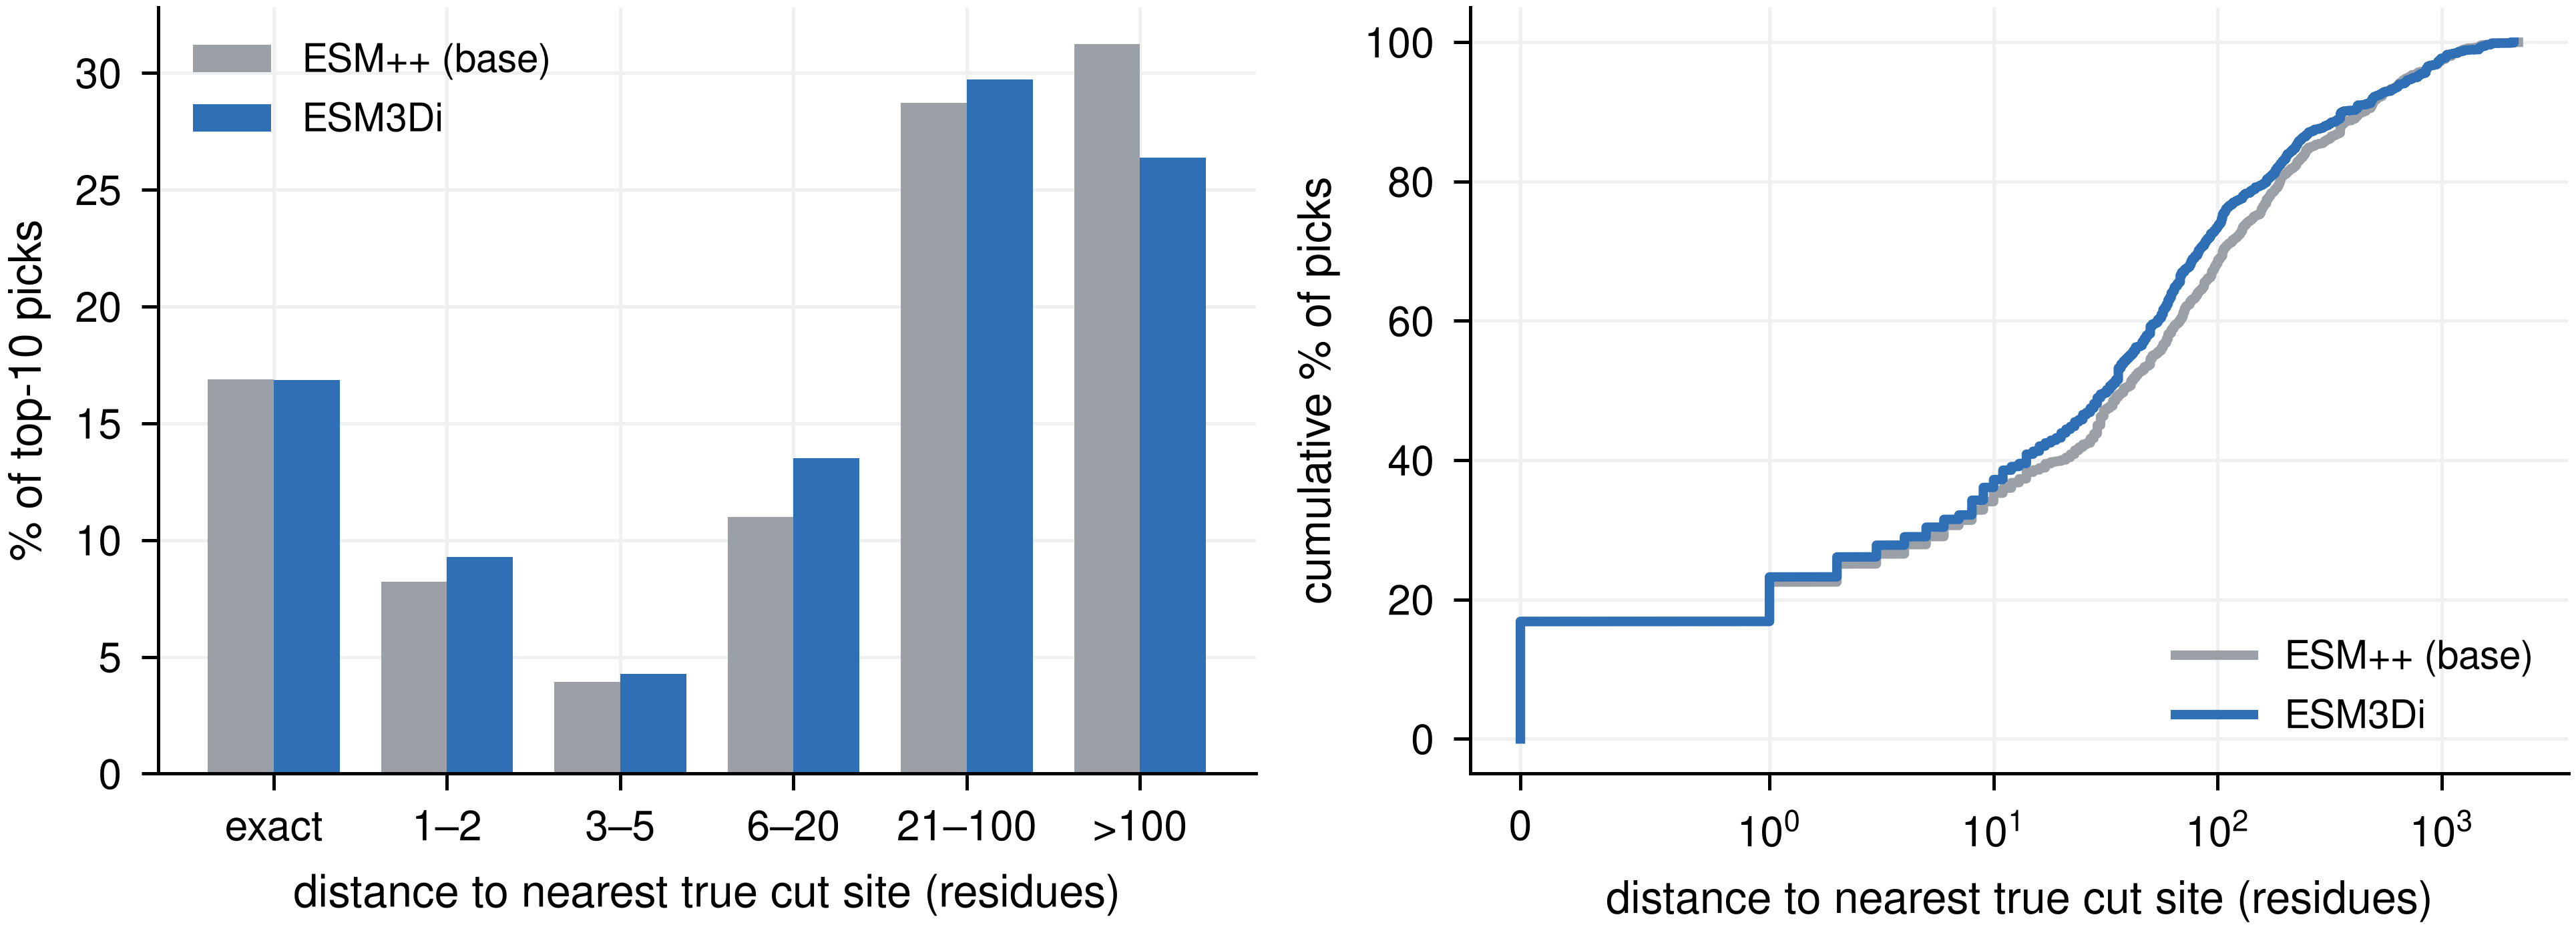

In [10]:
for name, width in (("paired_roc_auc.png", 390),
                    ("paired_delta.png", 400),
                    ("supp_fig_pick_distances.png", 720)):
    p = RESULTS / name
    if p.exists():
        print(name); display(Image(filename=str(p), width=width))

In [11]:
print("Supplementary table: all metrics, mean ± sd over seeds\n")
display(pd.read_csv(RESULTS / "supp_table_metrics.csv"))
dist = RESULTS / "supp_table_pick_distances.csv"
if dist.exists():
    print("\nDistance from each top-10 pick to the nearest annotated cut site\n")
    display(pd.read_csv(dist))

Supplementary table: all metrics, mean ± sd over seeds



,Held-out genus,Embeddings,n seq,n sites,ROC AUC,AP,AP ±2,AP ±5,top-10 recovery
0,Hepacivirus,ESM3Di,15,148,0.867 ± 0.010,0.078 ± 0.015,0.106 ± 0.009,0.127 ± 0.010,0.295 ± 0.028
1,Hepacivirus,ESM++ (base),15,148,0.845 ± 0.011,0.054 ± 0.008,0.110 ± 0.007,0.131 ± 0.007,0.286 ± 0.024
2,Orthoflavivirus,ESM3Di,31,347,0.913 ± 0.011,0.129 ± 0.034,0.159 ± 0.027,0.200 ± 0.025,0.261 ± 0.029
3,Orthoflavivirus,ESM++ (base),31,347,0.885 ± 0.020,0.129 ± 0.031,0.116 ± 0.021,0.145 ± 0.018,0.263 ± 0.030
4,Pegivirus,ESM3Di,21,112,0.884 ± 0.010,0.112 ± 0.043,0.103 ± 0.012,0.113 ± 0.011,0.577 ± 0.045
5,Pegivirus,ESM++ (base),21,112,0.827 ± 0.011,0.086 ± 0.034,0.101 ± 0.018,0.106 ± 0.013,0.426 ± 0.119
6,Pestivirus,ESM3Di,19,193,0.899 ± 0.019,0.148 ± 0.048,0.142 ± 0.032,0.146 ± 0.023,0.344 ± 0.040
7,Pestivirus,ESM++ (base),19,193,0.835 ± 0.017,0.165 ± 0.045,0.125 ± 0.017,0.124 ± 0.010,0.316 ± 0.031



Distance from each top-10 pick to the nearest annotated cut site



,distance (residues),ESM++ base (%),ESM3Di (%)
0,exact,16.9,16.8
1,1–2,8.2,9.3
2,3–5,3.9,4.3
3,6–20,11.0,13.5
4,21–100,28.7,29.7
5,>100,31.2,26.4
6,median distance,38.0,32.0
7,within 5 (%),29.0,30.4
8,within 20 (%),40.0,43.9
9,within 100 (%),68.8,73.6


### Supplementary table, as it appears in the brief communication

The same numbers in the layout used in the supplement: genus and fold sizes given once
per genus, with the second row carrying the base-model arm.

In [12]:
raw = pd.read_csv(RESULTS / "supp_table_metrics.csv")
paper = raw.copy()
blank = ["Held-out genus", "n seq", "n sites"]     # blank the repeat row of each genus
paper[blank] = paper[blank].astype(object)            # int columns cannot hold ""
paper.loc[paper.duplicated("Held-out genus"), blank] = ""
paper["Embeddings"] = paper["Embeddings"].str.replace(" (base)", "", regex=False)
paper.to_csv(RESULTS / "supp_table_metrics_formatted.csv", index=False)

display(paper.style.hide(axis="index"))
print("Cleavage sites are 0.28% of residues, so chance average precision is ~0.003.")

Held-out genus,Embeddings,n seq,n sites,ROC AUC,AP,AP ±2,AP ±5,top-10 recovery
Hepacivirus,ESM3Di,15,148,0.867 ± 0.010,0.078 ± 0.015,0.106 ± 0.009,0.127 ± 0.010,0.295 ± 0.028
,ESM++,,,0.845 ± 0.011,0.054 ± 0.008,0.110 ± 0.007,0.131 ± 0.007,0.286 ± 0.024
Orthoflavivirus,ESM3Di,31,347,0.913 ± 0.011,0.129 ± 0.034,0.159 ± 0.027,0.200 ± 0.025,0.261 ± 0.029
,ESM++,,,0.885 ± 0.020,0.129 ± 0.031,0.116 ± 0.021,0.145 ± 0.018,0.263 ± 0.030
Pegivirus,ESM3Di,21,112,0.884 ± 0.010,0.112 ± 0.043,0.103 ± 0.012,0.113 ± 0.011,0.577 ± 0.045
,ESM++,,,0.827 ± 0.011,0.086 ± 0.034,0.101 ± 0.018,0.106 ± 0.013,0.426 ± 0.119
Pestivirus,ESM3Di,19,193,0.899 ± 0.019,0.148 ± 0.048,0.142 ± 0.032,0.146 ± 0.023,0.344 ± 0.040
,ESM++,,,0.835 ± 0.017,0.165 ± 0.045,0.125 ± 0.017,0.124 ± 0.010,0.316 ± 0.031


Cleavage sites are 0.28% of residues, so chance average precision is ~0.003.


## Interpretation

ESM3Di embeddings separate cleavage sites better than non-fine-tuned ESM++ embeddings in
all four held-out genera. The gain is in the ranking rather than at residue resolution:
ROC AUC and the tolerance-window average precisions improve, while strict single-residue
average precision does not.

Standardising the features raises the measured gap relative to the raw-feature runs. The
direction of the result is the same either way; what changes is its size. Which protocol
to report is a judgement call: standardisation answers the objection that the two arms
might differ only in feature scale, but it also discards magnitude information that is
part of the representation, and it moves the two arms in opposite directions.

Limits worth stating with the result:

- The generalisation unit is the genus, so n = 4. The strength of the claim is the
  consistency across genera, not the size of the gap in any one of them.
- Strict AP is flat to negative. The supplementary table reports it.
- Four genera of one viral order, 800 annotated sites, labels transferred by homology
  rather than measured.
- This supports a representation-quality claim. It does not make the classifier a
  competitive cleavage-site predictor, and it is not presented as one.